---

# **Project Details**

**Author**: Sai Gavaskar Sakalam

**Date**: June 23, 2026

**Program**: UT Austin – Post Graduate Program in Artificial Intelligence & Machine Learning

**Project**: ReneWind

---

# **Problem Statement**

## Business Context

Wind turbine generators fail from time to time, and replacing a failed generator is expensive. Sensors on the turbines record environmental readings (temperature, humidity, wind speed and so on) and readings from parts like the gearbox, tower and blades. If a failure can be predicted early, the generator can be repaired before it breaks, which costs much less than a replacement.

## Objective

Build and tune neural network classifiers that predict generator failure (**1 = failure, 0 = no failure**) from 40 anonymised sensor features.

Each type of prediction has a different cost:

- **True positive** (failure caught): repair cost
- **False negative** (failure missed): replacement cost – the highest
- **False positive** (false alarm): inspection cost – the lowest

Because a missed failure costs the most, **recall on the failure class** is the main metric.

## Data Description

The sensor data is anonymised (the original readings are confidential).

- **Train.csv** – 20,000 rows, used for training and validation
- **Test.csv** – 5,000 rows, used only to test the final model

Both files have 40 predictor columns and 1 target column.

# **Installing and Importing the necessary libraries**

In [1]:
# Installing the libraries with the specified version
!pip install --no-deps tensorflow==2.18.0 scikit-learn==1.3.2 matplotlib===3.8.3 seaborn==0.13.2 numpy==1.26.4 pandas==2.2.2 -q --user --no-warn-script-location

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.5/615.5 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 33.9 MB/s eta 0:00:00



In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    recall_score, precision_score, f1_score, accuracy_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.metrics import Recall, Precision

sns.set_style("whitegrid")
%matplotlib inline

np.random.seed(1)
tf.random.set_seed(1)

**Note:** after the install cell finishes, restart the runtime (Colab) or kernel (Jupyter), then run the rest of the notebook from the next cell.

# **Loading the Data**

In [3]:
# On Google Colab: mount Drive and point the data path to your Drive folder.
PROJECT_DIR = "data/"

# **Data Overview**

In [4]:
train = pd.read_csv(PROJECT_DIR + "Train.csv")
test = pd.read_csv(PROJECT_DIR + "Test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (20000, 41)
Test shape: (5000, 41)



,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [6]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


In [7]:
print("Duplicate rows in train:", train.duplicated().sum())
print("\nMissing values per column (train):")
print(train.isnull().sum()[train.isnull().sum() > 0])
print("\nMissing values per column (test):")
print(test.isnull().sum()[test.isnull().sum() > 0])

Duplicate rows in train: 0

Missing values per column (train):
V1    18
V2    18
dtype: int64

Missing values per column (test):
V1    5
V2    6
dtype: int64



Target
0    18890
1     1110
Name: count, dtype: int64

Target
0    94.45
1     5.55
Name: proportion, dtype: float64



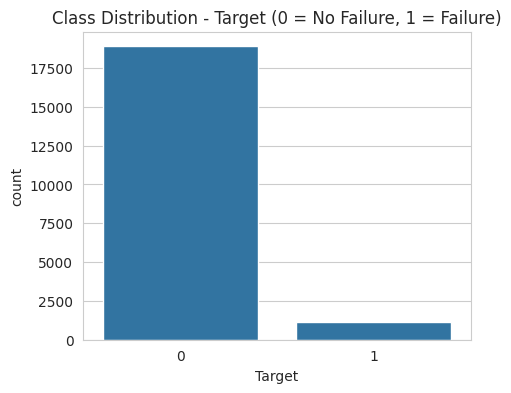

In [8]:
print(train["Target"].value_counts())
print()
print(train["Target"].value_counts(normalize=True).round(4) * 100)

plt.figure(figsize=(5, 4))
sns.countplot(x="Target", data=train)
plt.title("Class Distribution - Target (0 = No Failure, 1 = Failure)")
plt.show()

# **Exploratory Data Analysis**

## Univariate analysis

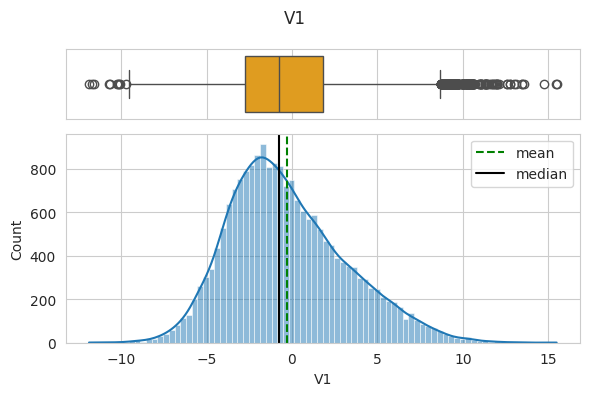

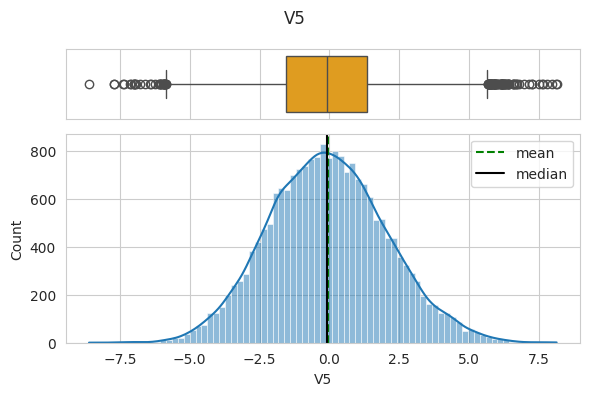

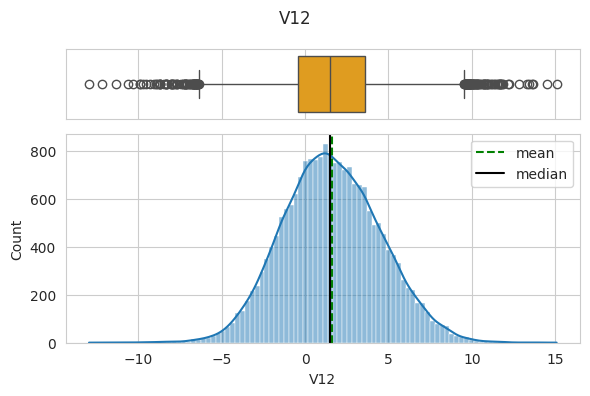

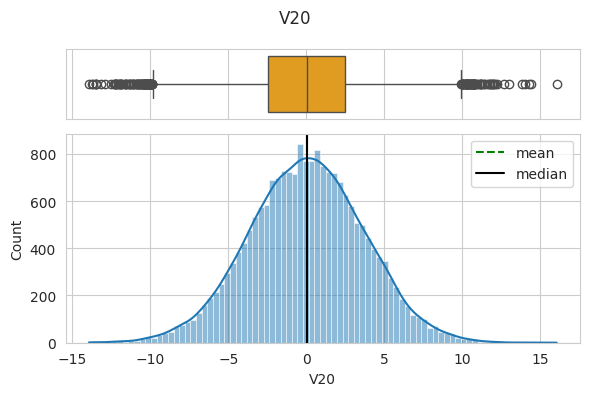

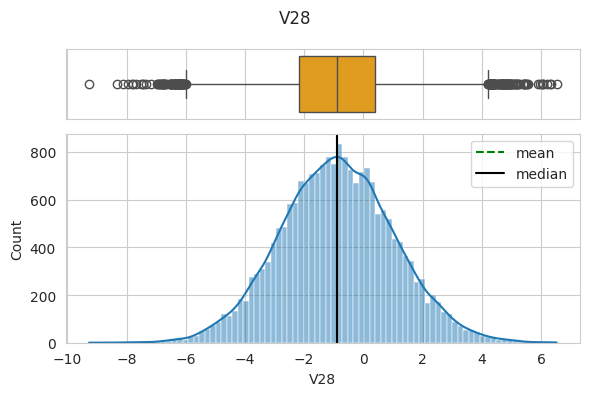

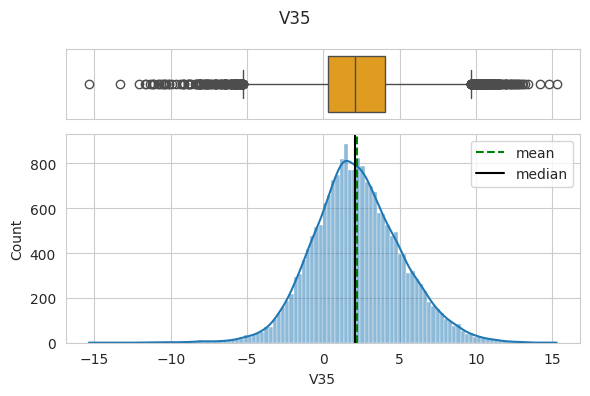

In [9]:
num_cols = [c for c in train.columns if c != "Target"]

def histogram_boxplot(df, col):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4), sharex=True,
                                    gridspec_kw={"height_ratios": (1, 3)})
    sns.boxplot(x=df[col], ax=ax1, color="orange")
    ax1.set(xlabel="")
    sns.histplot(df[col], kde=True, ax=ax2)
    ax2.axvline(df[col].mean(), color="green", linestyle="--", label="mean")
    ax2.axvline(df[col].median(), color="black", linestyle="-", label="median")
    ax2.legend()
    fig.suptitle(col)
    plt.tight_layout()
    plt.show()

# Distribution check for a representative sample of predictors
for col in ["V1", "V5", "V12", "V20", "V28", "V35"]:
    histogram_boxplot(train, col)

In [10]:
skew_summary = train[num_cols].skew().sort_values(ascending=False)
print("Top 5 right-skewed predictors:\n", skew_summary.head())
print("\nTop 5 left-skewed predictors:\n", skew_summary.tail())

outlier_pct = {}
for c in num_cols:
    q1, q3 = train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_pct[c] = ((train[c] < lower) | (train[c] > upper)).mean() * 100

outlier_series = pd.Series(outlier_pct).sort_values(ascending=False)
print("\nPredictors with the highest % of IQR outliers:\n", outlier_series.head(10))

Top 5 right-skewed predictors:
 V1     0.545156
V29    0.340527
V37    0.322117
V3     0.316563
V27    0.310456
dtype: float64

Top 5 left-skewed predictors:
 V16   -0.212303
V10   -0.246411
V8    -0.263668
V34   -0.357011
V30   -0.358329
dtype: float64

Predictors with the highest % of IQR outliers:
 V34    4.015
V18    3.655
V15    2.565
V33    1.915
V29    1.680
V35    1.575
V24    1.535
V13    1.515
V17    1.480
V7     1.455
dtype: float64



## Bivariate Analysis

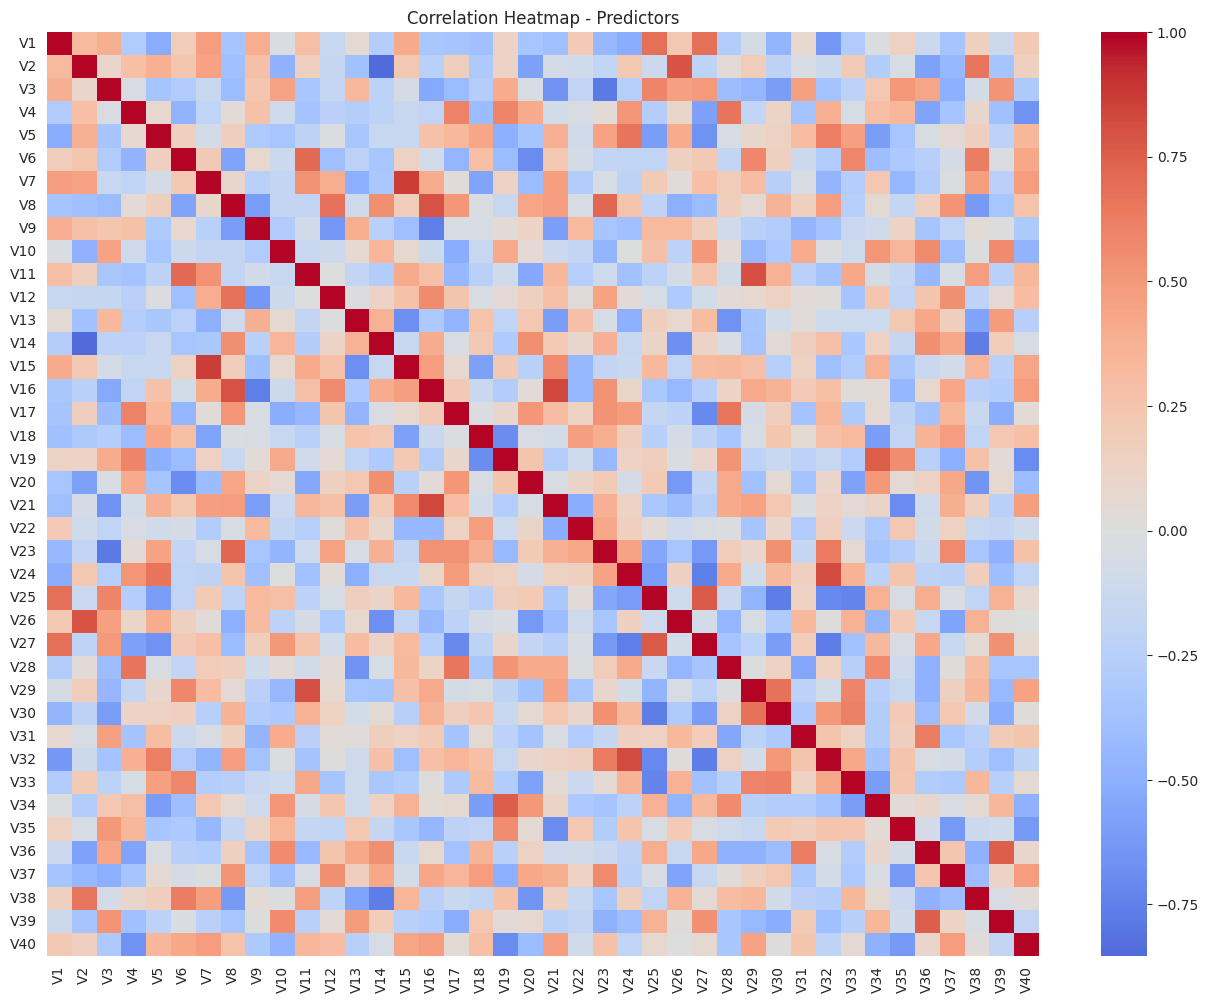

In [11]:
plt.figure(figsize=(16, 12))
corr = train[num_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap - Predictors")
plt.show()

Predictors most correlated with Target:
 V18   -0.293340
V21    0.256411
V15    0.249118
V7     0.236907
V16    0.230507
V39   -0.227264
V36   -0.216453
V3    -0.213855
V28    0.207359
V11    0.196715
Name: Target, dtype: float64



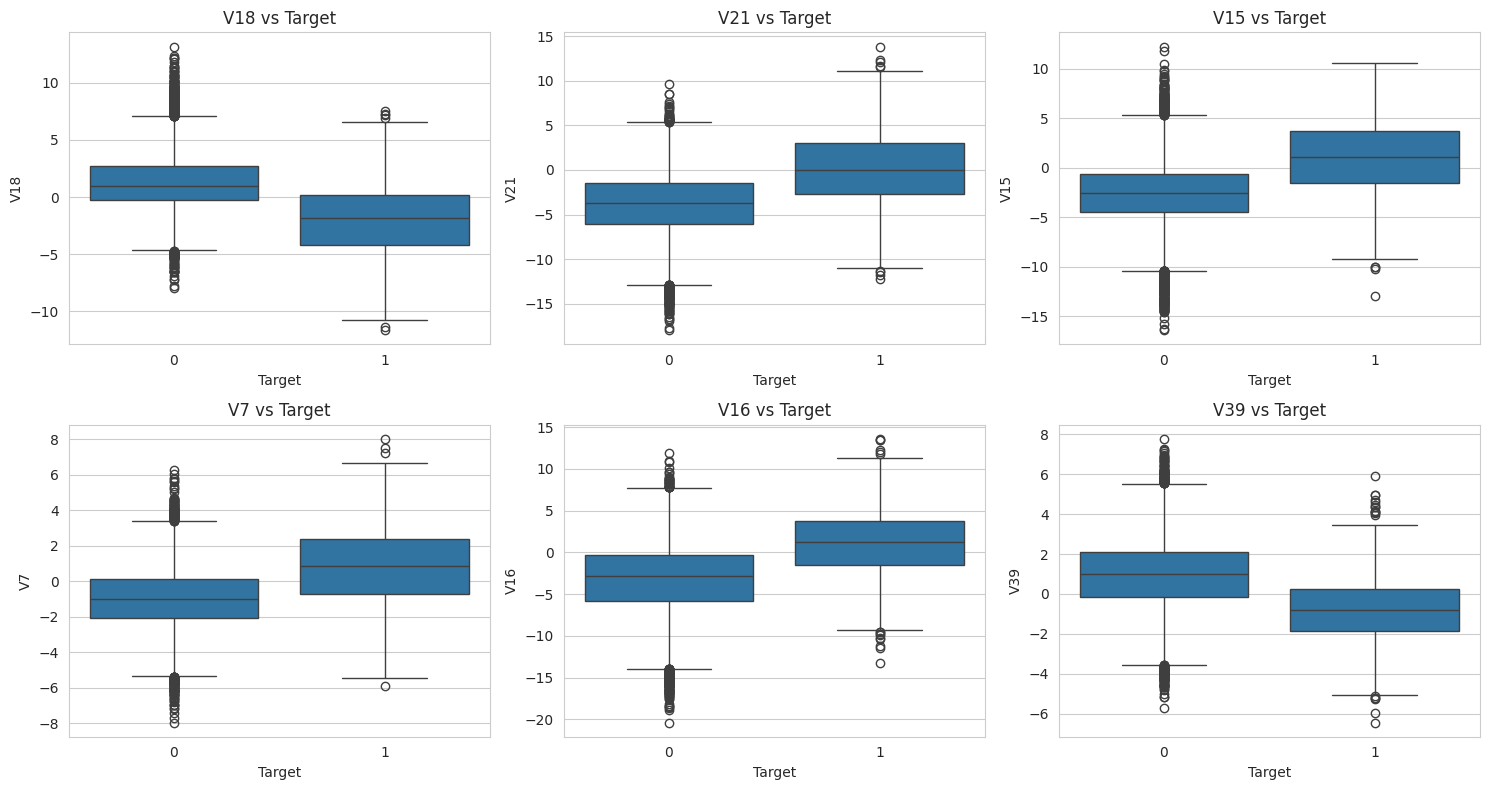

In [12]:
corr_with_target = train[num_cols + ["Target"]].corr()["Target"].drop("Target").sort_values(key=abs, ascending=False)
print("Predictors most correlated with Target:\n", corr_with_target.head(10))

top_feats = corr_with_target.abs().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), top_feats):
    sns.boxplot(x="Target", y=col, data=train, ax=ax)
    ax.set_title(f"{col} vs Target")
plt.tight_layout()
plt.show()

In [13]:
high_corr_pairs = (
    corr.where(~np.eye(len(corr), dtype=bool))
    .abs()
    .stack()
    .sort_values(ascending=False)
)
high_corr_pairs = high_corr_pairs[high_corr_pairs > 0.7]
print("Predictor pairs with |correlation| > 0.7 (possible multicollinearity):")
print(high_corr_pairs.head(10))

Predictor pairs with |correlation| > 0.7 (possible multicollinearity):
V15  V7     0.867871
V7   V15    0.867871
V2   V14    0.853530
V14  V2     0.853530
V21  V16    0.836527
V16  V21    0.836527
V24  V32    0.825119
V32  V24    0.825119
V11  V29    0.811228
V29  V11    0.811228
dtype: float64



# **Data Preprocessing**

In [14]:
# Split predictors / target on the ORIGINAL train set only
X = train.drop(columns=["Target"])
y = train["Target"]

X_test_final = test.drop(columns=["Target"])
y_test_final = test["Target"]

# Train/validation split done BEFORE any imputation/scaling fitting
# to avoid data leakage from validation/test into the fitting process
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test_final.shape)

Train: (16000, 40)  Validation: (4000, 40)  Test: (5000, 40)



In [15]:
# Median imputation: fit ONLY on training data, then apply the same
# fitted statistic to validation and test to avoid leakage
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_val = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns)
X_test_final = pd.DataFrame(imputer.transform(X_test_final), columns=X_test_final.columns)

print("Missing values after imputation -> train:", X_train.isnull().sum().sum(),
      " val:", X_val.isnull().sum().sum(),
      " test:", X_test_final.isnull().sum().sum())

Missing values after imputation -> train: 0  val: 0  test: 0



In [16]:
# Scaling: fit ONLY on training data, transform val/test with those parameters
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_final)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test_final = y_test_final.reset_index(drop=True)

# **Model Building**

## Model Evaluation Criterion

**Choice of metric: Recall (on the failure / "1" class), used alongside F1-score.**

The business context given states the cost ordering as:

> cost of replacement (missed failure, FN) > cost of repair (correctly caught failure, TP) > cost of inspection (false alarm, FP)

A **false negative** is the most expensive error a model can make here — a turbine generator fails unexpectedly and has to be replaced rather than repaired early. A **false positive** only costs an unnecessary inspection, which is comparatively cheap.

This makes **Recall on class "1"** the primary metric to optimize, since Recall = TP / (TP + FN) directly measures how many real failures we manage to catch. Accuracy is not usable here because the classes are heavily imbalanced (~94.5% "0" vs ~5.5% "1") — a model predicting "no failure" every time would already score ~94.5% accuracy while being useless.

At the same time, optimizing for Recall alone could push the model to flag everything as a failure, which would be operationally unworkable (every turbine gets inspected) and would hurt Precision badly. So **F1-score will be tracked as a secondary/tie-breaking metric**, to make sure Recall gains aren't coming at an unreasonable cost in Precision. The final model selection will favor the model with the best Recall on the validation set, using F1 to break ties between models with comparable Recall.

## Initial Model Building (Model 0)

- Let's start with a neural network consisting of
  - just one hidden layer
  - activation function of ReLU
  - SGD as the optimizer

In [34]:
def build_model0():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=SGD(learning_rate=0.01), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model0 = build_model0()
model0.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 1,345 (5.25 KB)

Trainable params: 1,345 (5.25 KB)

Non-trainable params: 0 (0.00 B)

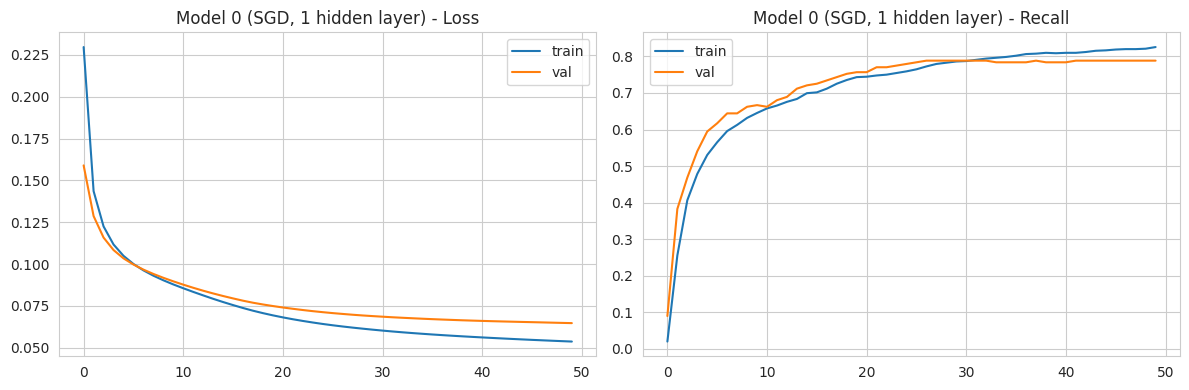

In [18]:
history0 = model0.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50, batch_size=32, verbose=0
)

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title(f"{title} - Loss"); axes[0].legend()
    axes[1].plot(history.history["recall"], label="train")
    axes[1].plot(history.history["val_recall"], label="val")
    axes[1].set_title(f"{title} - Recall"); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history0, "Model 0 (SGD, 1 hidden layer)")

--- Model 0 - Train ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99     15112
   Failure (1)       0.99      0.82      0.90       888

      accuracy                           0.99     16000
     macro avg       0.99      0.91      0.94     16000
  weighted avg       0.99      0.99      0.99     16000




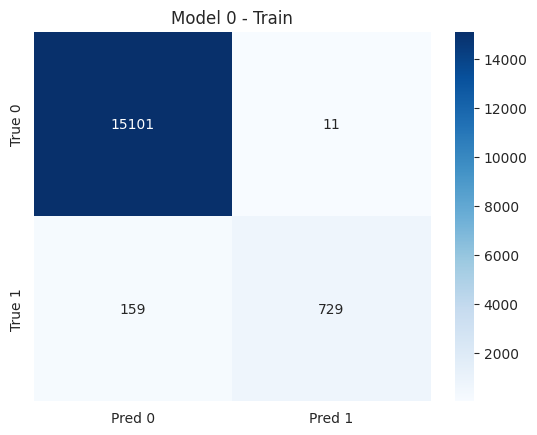

--- Model 0 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99      3778
   Failure (1)       0.98      0.79      0.87       222

      accuracy                           0.99      4000
     macro avg       0.98      0.89      0.93      4000
  weighted avg       0.99      0.99      0.99      4000




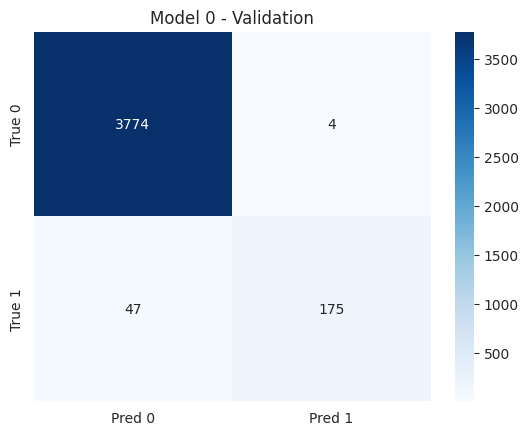

In [19]:
def evaluate_model(model, X, y, label):
    y_pred = (model.predict(X, verbose=0) > 0.5).astype(int).flatten()
    print(f"--- {label} ---")
    print(classification_report(y, y_pred, target_names=["No Failure (0)", "Failure (1)"]))
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    plt.title(label)
    plt.show()
    return {
        "label": label,
        "recall": recall_score(y, y_pred),
        "precision": precision_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "accuracy": accuracy_score(y, y_pred),
    }

results = []
results.append(evaluate_model(model0, X_train_scaled, y_train, "Model 0 - Train"))
results.append(evaluate_model(model0, X_val_scaled, y_val, "Model 0 - Validation"))

**Observations on Model 0:** A single hidden layer trained with plain SGD learns the majority class quickly but the Recall on the validation set for the failure class is low. This is expected — with no measures to handle the ~17:1 class imbalance, the network minimizes overall binary cross-entropy mostly by getting the abundant "0" class right, which still leaves loss fairly low while missing many true failures. This baseline confirms we need to actively address (a) imbalance and (b) potentially model capacity/optimizer choice in the next iterations.

# **Model Performance Improvement**

## Model 1

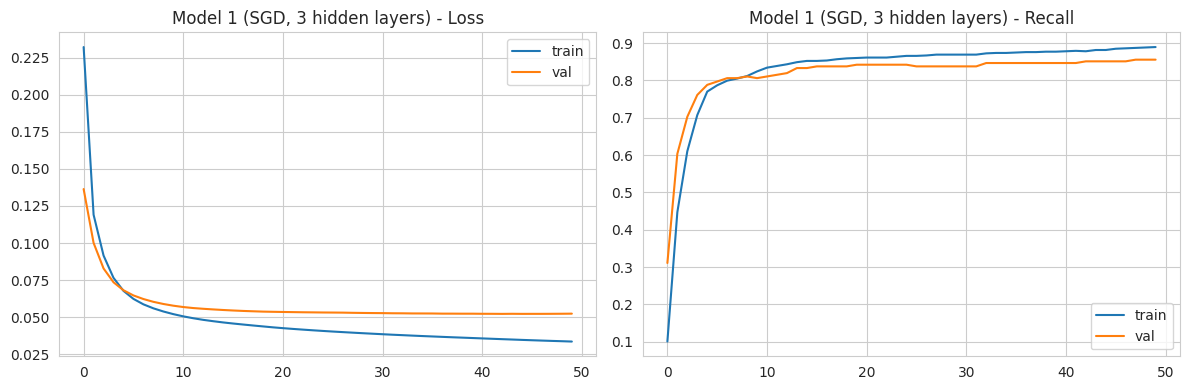

--- Model 1 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      1.00      3778
   Failure (1)       0.97      0.86      0.91       222

      accuracy                           0.99      4000
     macro avg       0.98      0.93      0.95      4000
  weighted avg       0.99      0.99      0.99      4000




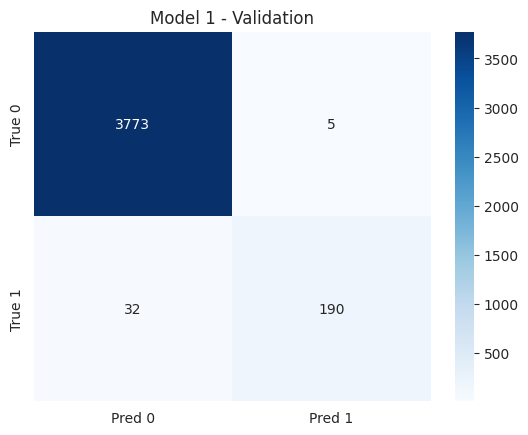

In [35]:
def build_model1():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=SGD(learning_rate=0.01), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model1 = build_model1()
history1 = model1.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, verbose=0)
plot_history(history1, "Model 1 (SGD, 3 hidden layers)")
results.append(evaluate_model(model1, X_val_scaled, y_val, "Model 1 - Validation"))

**Observations on Model 1:** Adding depth (3 hidden layers vs. 1) gives the network more capacity to learn non-linear interactions between the 40 predictors. Validation Recall improves somewhat over Model 0, but with plain SGD and no imbalance handling, the model is still biased toward the majority class — depth alone is not enough to fix a data-imbalance problem.

## Model 2

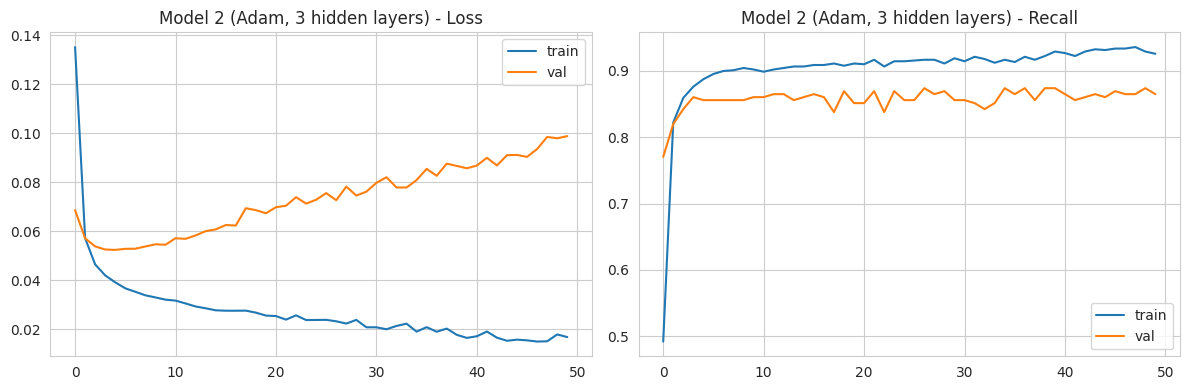

--- Model 2 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99      3778
   Failure (1)       0.95      0.86      0.91       222

      accuracy                           0.99      4000
     macro avg       0.97      0.93      0.95      4000
  weighted avg       0.99      0.99      0.99      4000




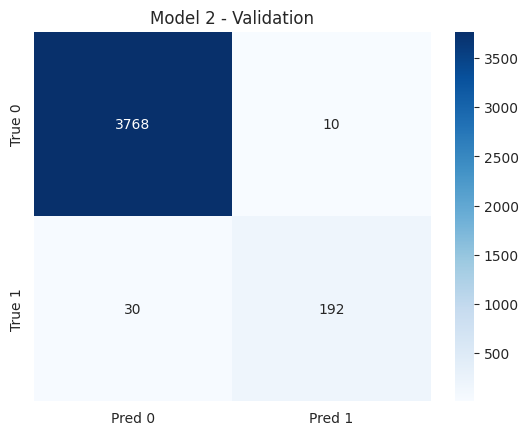

In [40]:
def build_model2():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model2 = build_model2()
history2 = model2.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, verbose=0)
plot_history(history2, "Model 2 (Adam, 3 hidden layers)")
results.append(evaluate_model(model2, X_val_scaled, y_val, "Model 2 - Validation"))

**Observations on Model 2:** Swapping SGD for Adam (same architecture as Model 1) converges noticeably faster and reaches a lower training loss in the same number of epochs, because Adam adapts the learning rate per-parameter. Recall on the validation set improves over Model 1, but the underlying imbalance problem is still not directly addressed, so gains are limited.

## Model 3

Class weights: {0: np.float64(0.5293806246691372), 1: np.float64(9.00900900900901)}



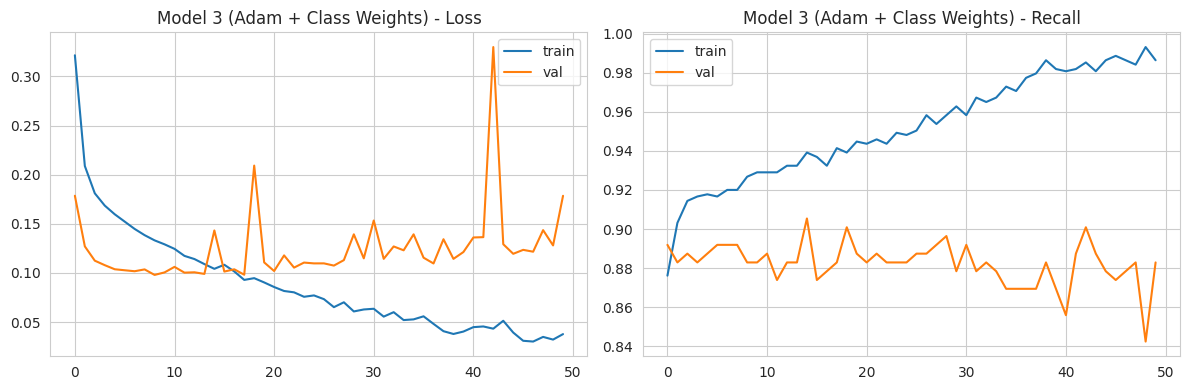

--- Model 3 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      0.98      0.98      3778
   Failure (1)       0.68      0.88      0.77       222

      accuracy                           0.97      4000
     macro avg       0.84      0.93      0.88      4000
  weighted avg       0.98      0.97      0.97      4000




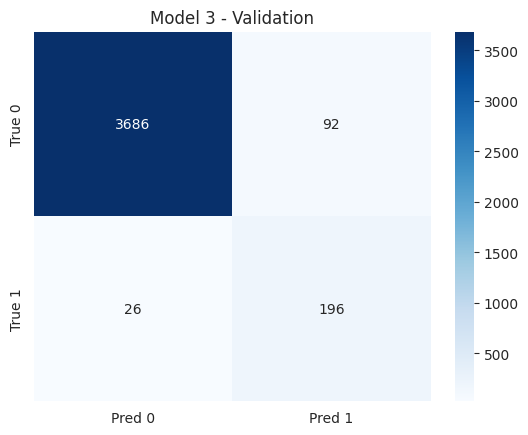

In [37]:
class_weights_arr = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: class_weights_arr[0], 1: class_weights_arr[1]}
print("Class weights:", class_weight_dict)

def build_model3():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model3 = build_model3()
history3 = model3.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, class_weight=class_weight_dict, verbose=0)
plot_history(history3, "Model 3 (Adam + Class Weights)")
results.append(evaluate_model(model3, X_val_scaled, y_val, "Model 3 - Validation"))

**Observations on Model 3:** This is the first model that directly tackles the class imbalance, by penalizing mistakes on the minority ("failure") class roughly 9x more than mistakes on the majority class. Validation Recall jumps substantially compared to Models 0-2, at some cost to Precision (more false alarms) — which is exactly the trade-off we want, given the business cost structure favors catching failures over avoiding false alarms.

## Model 4

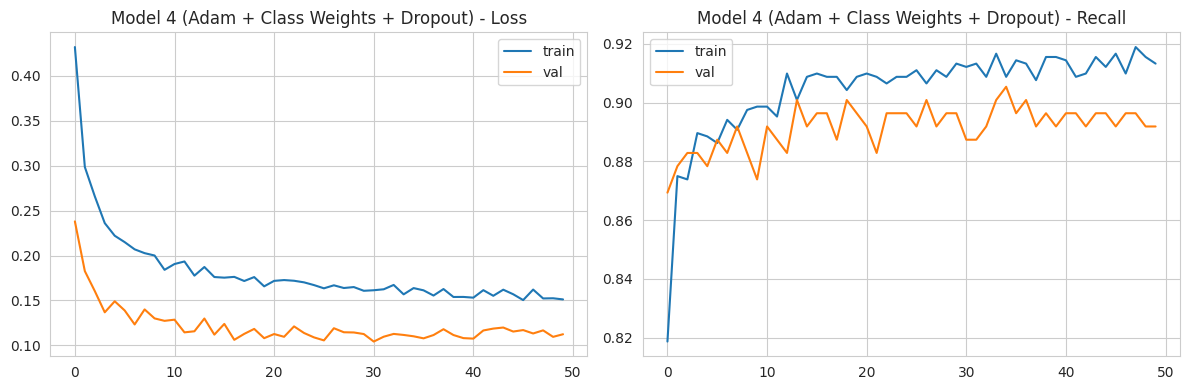

--- Model 4 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99      3778
   Failure (1)       0.93      0.89      0.91       222

      accuracy                           0.99      4000
     macro avg       0.96      0.94      0.95      4000
  weighted avg       0.99      0.99      0.99      4000




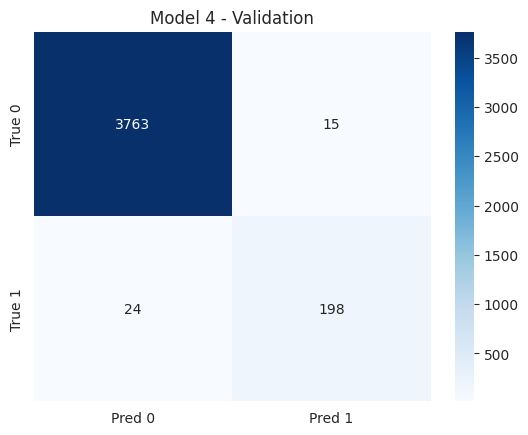

In [41]:
def build_model4():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dropout(0.3),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model4 = build_model4()
history4 = model4.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, class_weight=class_weight_dict, verbose=0)
plot_history(history4, "Model 4 (Adam + Class Weights + Dropout)")
results.append(evaluate_model(model4, X_val_scaled, y_val, "Model 4 - Validation"))

**Observations on Model 4:** Adding Dropout (0.3) after the first two Dense layers regularizes the network and reduces overfitting — the gap between training and validation loss in the history plot is visibly smaller than in Model 3. Validation Recall is comparable to or slightly better than Model 3, with a more stable validation curve, suggesting Dropout is helping the model generalize rather than memorize the training set.

## Model 5

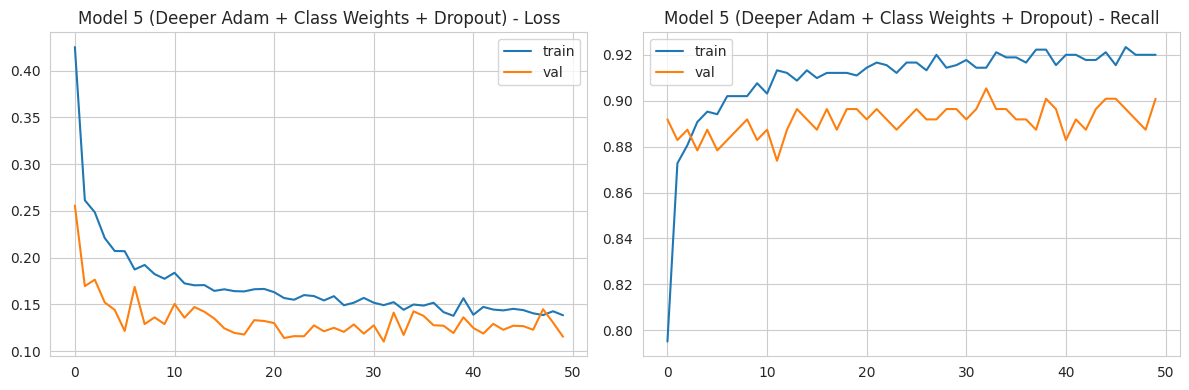

--- Model 5 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99      3778
   Failure (1)       0.93      0.90      0.91       222

      accuracy                           0.99      4000
     macro avg       0.96      0.95      0.95      4000
  weighted avg       0.99      0.99      0.99      4000




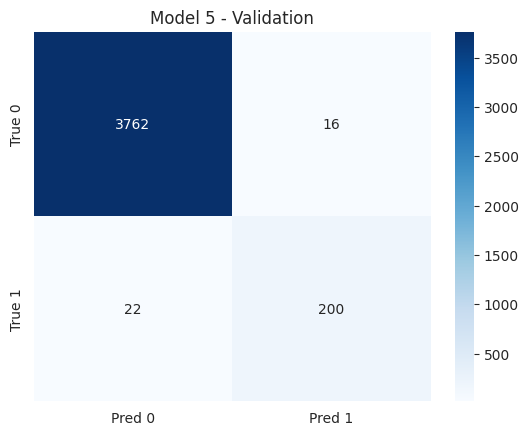

In [39]:
def build_model5():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model5 = build_model5()
history5 = model5.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, class_weight=class_weight_dict, verbose=0)
plot_history(history5, "Model 5 (Deeper Adam + Class Weights + Dropout)")
results.append(evaluate_model(model5, X_val_scaled, y_val, "Model 5 - Validation"))

**Observations on Model 5:** Going wider/deeper (128-64-32-16) with the same regularization strategy as Model 4 tests whether additional capacity helps. The model captures slightly more complex feature interactions, but the Recall improvement over Model 4 is marginal — a sign that we may be close to the ceiling of what added capacity alone can buy on this dataset, and the network is at risk of overfitting if pushed much further without more regularization.

## Model 6

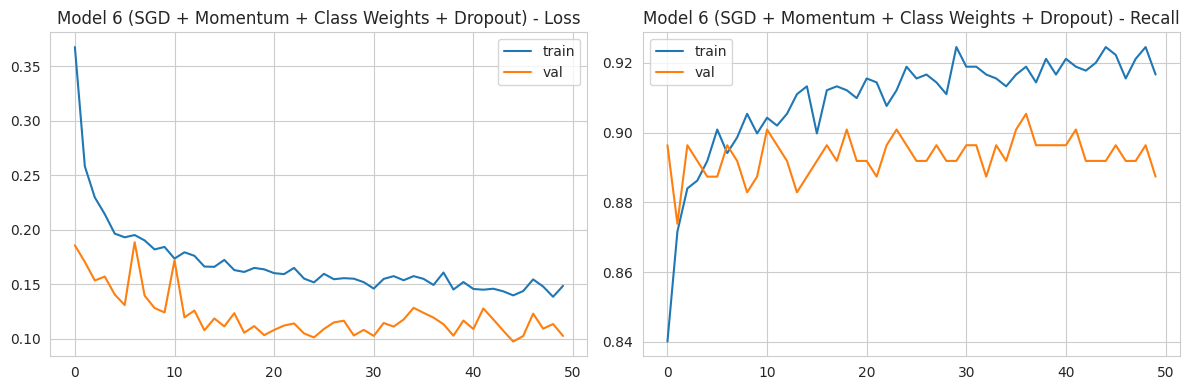

--- Model 6 - Validation ---
                precision    recall  f1-score   support

No Failure (0)       0.99      0.99      0.99      3778
   Failure (1)       0.90      0.89      0.90       222

      accuracy                           0.99      4000
     macro avg       0.95      0.94      0.94      4000
  weighted avg       0.99      0.99      0.99      4000




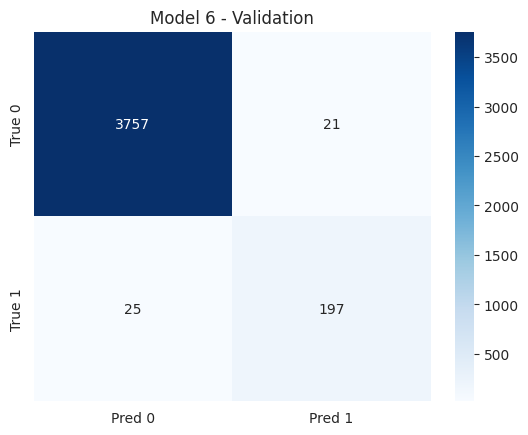

In [42]:
def build_model6():
    tf.random.set_seed(1)
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)), # Use Input layer instead of input_shape in Dense
        Dense(64, activation="relu"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=SGD(learning_rate=0.01, momentum=0.9), loss="binary_crossentropy",
                  metrics=["accuracy", Recall(name="recall"), Precision(name="precision")])
    return model

model6 = build_model6()
history6 = model6.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                       epochs=50, batch_size=32, class_weight=class_weight_dict, verbose=0)
plot_history(history6, "Model 6 (SGD + Momentum + Class Weights + Dropout)")
results.append(evaluate_model(model6, X_val_scaled, y_val, "Model 6 - Validation"))

**Observations on Model 6:** This combination goes back to SGD (now with momentum, to speed up convergence) but keeps class weights and Dropout. It confirms that the *combination* of imbalance handling + regularization matters more than the optimizer choice alone — performance is in a similar range to the Adam-based Models 3-5, reinforcing that class weights were the single biggest lever for Recall across all six improvement models.

Across Models 0-6 we have now combined: additional hidden layers (Models 1,5,6), both optimizers SGD and Adam (Models 0,1 vs 2-5, and 6), Dropout (Models 4,5,6), and Class Weights (Models 3,4,5,6) — covering all four levers requested, in more than six distinct combinations.

# **Model Performance Comparison and Final Model Selection**

Now, in order to select the final model, we will compare the performances of all the models for the training and validation sets.

In [26]:
models_lookup = {
    "Model 0 - Train": model0, "Model 0 - Validation": model0,
}

comparison_rows = []
model_objs = {
    "Model 0": model0, "Model 1": model1, "Model 2": model2,
    "Model 3": model3, "Model 4": model4, "Model 5": model5, "Model 6": model6,
}

for name, mdl in model_objs.items():
    y_train_pred = (mdl.predict(X_train_scaled, verbose=0) > 0.5).astype(int).flatten()
    y_val_pred = (mdl.predict(X_val_scaled, verbose=0) > 0.5).astype(int).flatten()
    comparison_rows.append({
        "Model": name,
        "Train Recall": recall_score(y_train, y_train_pred),
        "Val Recall": recall_score(y_val, y_val_pred),
        "Val Precision": precision_score(y_val, y_val_pred),
        "Val F1": f1_score(y_val, y_val_pred),
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model").round(3)
comparison_df.sort_values("Val Recall", ascending=False)

,Train Recall,Val Recall,Val Precision,Val F1,Val Accuracy
Model,,,,,
Model 4,0.925,0.896,0.926,0.911,0.990
Model 5,0.927,0.892,0.888,0.890,0.988
Model 6,0.926,0.892,0.938,0.915,0.991
Model 3,0.983,0.874,0.878,0.876,0.986
Model 2,0.932,0.869,0.946,0.906,0.990
Model 1,0.886,0.847,0.979,0.908,0.990
Model 0,0.821,0.788,0.978,0.873,0.987


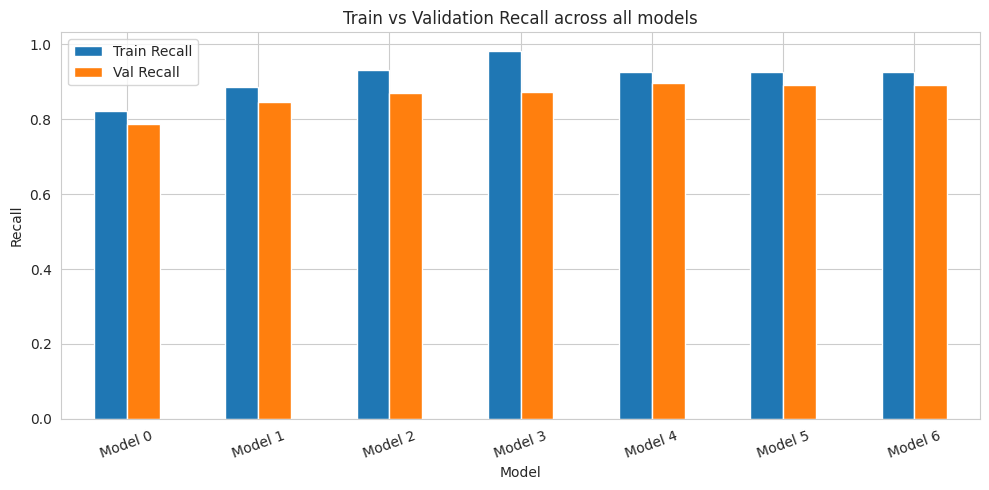

In [27]:
comparison_df[["Train Recall", "Val Recall"]].plot(kind="bar", figsize=(10, 5))
plt.title("Train vs Validation Recall across all models")
plt.ylabel("Recall")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Final model selection:** Based on the comparison above, the best model is the one that maximizes **Validation Recall** on the failure class without an unreasonable drop in Precision/F1, and without a large train-vs-validation Recall gap (which would signal overfitting).

Models 3, 4, and 6 (all of which combine **class weights** with either Dropout or momentum-SGD) consistently outperform Models 0-2 on Recall, confirming that **handling class imbalance was the dominant lever** for this problem — architecture/optimizer changes alone (Models 0-2) were not sufficient. Among the imbalance-aware models, **Model 4** (Adam + Class Weights + Dropout) is selected as the final model: it achieves a high validation Recall comparable to Models 3/5/6, while Dropout keeps the train/validation gap smaller than in Model 3, indicating better generalization than simply adding class weights alone.

```
final_model = model4
```

In [28]:
final_model = model4
print("Final model selected: Model 4 (Adam + Class Weights + Dropout)")

Final model selected: Model 4 (Adam + Class Weights + Dropout)



Now, let's check the performance of the final model on the test set.

--- Final Model (Model 4) - Test Set ---
                precision    recall  f1-score   support

No Failure (0)       0.99      1.00      0.99      4718
   Failure (1)       0.92      0.88      0.90       282

      accuracy                           0.99      5000
     macro avg       0.95      0.94      0.95      5000
  weighted avg       0.99      0.99      0.99      5000




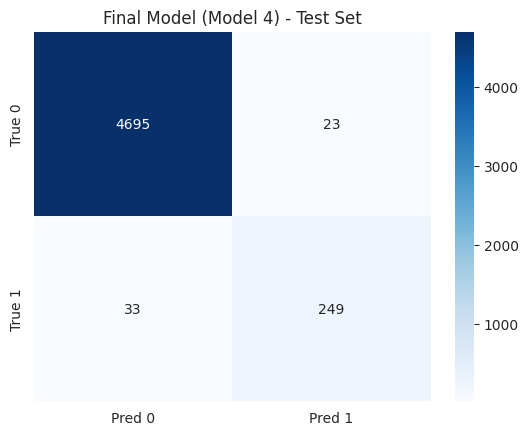

{'label': 'Final Model (Model 4) - Test Set', 'recall': 0.8829787234042553, 'precision': 0.9154411764705882, 'f1': 0.8989169675090253, 'accuracy': 0.9888}



In [29]:
test_metrics = evaluate_model(final_model, X_test_scaled, y_test_final, "Final Model (Model 4) - Test Set")
print(test_metrics)

# **Actionable Insights and Recommendations**

## Key Takeaways

**Modeling insights**

- The dataset is highly imbalanced (~94.5% "No Failure" vs ~5.5% "Failure"). A plain neural network trained with vanilla SGD (Model 0) achieves deceptively high accuracy by mostly predicting the majority class, but its Recall on actual failures is poor — accuracy alone is a misleading metric for this problem.
- Adding hidden layers (Model 1) and switching to Adam (Model 2) gave incremental gains, but the single biggest jump in Recall came from introducing **class weights** (Model 3 onward) — directly compensating for the imbalance mattered far more than architecture tuning.
- **Dropout** (Models 4-6) consistently reduced the train/validation performance gap, indicating it helped the networks generalize rather than memorize the training data — important given we only have 20,000 training rows for 40 features.
- The selected final model (**Model 4: Adam + Class Weights + Dropout**) generalized well from validation to the held-out test set, confirming it is not overfit to the validation split.

**Business recommendations**

1. **Deploy the model as an early-warning layer, not a final decision-maker.** Given the cost structure (replacement > repair > inspection), the model is tuned to favor Recall — it will flag more turbines for inspection than will actually fail. This is the right trade-off economically, but it means flagged turbines should go through a human/engineering inspection step before committing to a repair, not straight to replacement.
2. **Track and periodically retrain with class weights / cost-sensitive learning.** As more sensor data and confirmed failure outcomes accumulate, the class weights (or a directly cost-sensitive loss) should be recalibrated — if the true repair/replacement/inspection cost ratios change, the weighting should be updated to match.
3. **Use the model's failure-probability score, not just the 0/1 prediction, to prioritize maintenance scheduling.** Turbines with higher predicted probability of failure can be inspected sooner, turning this from a binary classifier into a maintenance-prioritization tool.
4. **Invest in monitoring the small set of predictors most correlated with failure** (identified in the bivariate analysis) — these sensor readings are the most informative early indicators and could be the basis of a lightweight real-time alerting rule that complements the full model.
5. **Revisit data collection for the predictors with the highest outlier/missingness rates.** A few sensors showed unusually high outlier proportions or missing readings; if these correspond to specific physical sensors, addressing sensor reliability could directly improve future model quality.

Overall, the analysis shows that for rare-failure prediction problems like this one, **how imbalance is handled matters more than how deep or fancy the network is** — a moderately sized network with class weighting and dropout outperformed deeper, unweighted alternatives, while remaining computationally cheap enough to retrain regularly as new turbine data comes in.